# Aprendizado Semissupervisionado com Digits: Baseline Supervisionado × Self-Training × Label Spreading

**Dataset:** `sklearn.datasets.load_digits` (1.797 amostras, imagens $8 \times 8$ pixels = 64 atributos, 10 classes)  
**Comparação Principal:** Baseline Supervisionado (`SVC` apenas nos dados rotulados) × `SelfTrainingClassifier` × `LabelSpreading` (+ `LabelPropagation` e Teto Supervisionado 100%)

---

## 1. Introdução, Objetivo e Hipóteses

Em diversos problemas reais de reconhecimento de padrões, coletar exemplos não rotulados é barato e abundante, enquanto a anotação manual por especialistas é cara e demorada. O **Aprendizado Semissupervisionado (SSL)** busca explorar a estrutura geométrica ou distribucional de um conjunto grande de amostras não rotuladas $X_U$ em conjunto com um pequeno subconjunto rotulado $(X_L, y_L)$ para construir classificadores superiores àqueles treinados exclusivamente em $X_L$.

### Objetivo
Medir quantitativamente e qualitativamente o ganho proporcionado pelos dados **não rotulados** no dataset **Digits** sob diferentes regimes de escassez de rótulos (**2%, 5%, 10% e 20%** do conjunto de treinamento rotulado), avaliando tanto a generalização **indutiva** (no conjunto de teste) quanto a qualidade **transdutiva** (acurácia dos pseudo-rótulos atribuídos às amostras de treino mascaradas).

### Hipóteses Experimentais
- **H1 (Vantagem em baixa supervisão):** Com poucos rótulos disponíveis, os métodos semissupervisionados (*Self-Training* e *Label Spreading*) superam o *Baseline* supervisionado.
- **H2 (Convergência assintótica):** Conforme a fração de dados rotulados cresce (de 2% até 20%), a vantagem relativa dos métodos semissupervisionados diminui e as curvas de desempenho convergem em direção ao teto supervisionado (100% dos rótulos).
- **H3 (Adequação da suposição de variedade/cluster no Digits):** O *Label Spreading* tende a obter excelente desempenho no dataset *Digits* porque as classes de dígitos manuscritos formam agrupamentos (*clusters*) bem definidos no espaço de atributos (suposição de *cluster* e suavidade no grafo de vizinhança).
- **H4 (Sensibilidade e *Confirmation Bias* no Self-Training):** O *Self-Training* é fortemente sensível ao critério de seleção (`threshold` ou `k_best`) e à calibração das probabilidades iniciais: limiares muito baixos ou escolhas forçadas com poucos rótulos introduzem pseudo-rótulos incorretos que são reforçados iterativamente (*confirmation bias*), enquanto limiares altos em regimes extremos (2%) podem impedir a aceitação de novos exemplos.

---

## 2. Fundamentação Teórica

O aprendizado semissupervisionado apoia-se em três suposições fundamentais (Chapelle et al., 2006):
1. **Suposição de Suavidade (*Smoothness Assumption*):** Se dois pontos $x_1, x_2$ estão próximos em uma região de alta densidade, então suas saídas correspondentes $y_1, y_2$ devem ser iguais ou muito próximas.
2. **Suposição de Cluster (*Cluster Assumption*):** Se os pontos estão no mesmo agrupamento (*cluster*) de alta densidade, eles provavelmente pertencem à mesma classe (equivalentemente, a fronteira de decisão deve passar por regiões de baixa densidade).
3. **Suposição de Variedade (*Manifold Assumption*):** Os dados de alta dimensão ($\mathbb{R}^{64}$) distribuem-se próximos a variedades de menor dimensão onde distâncias geodésicas (capturadas por grafos de $k$-vizinhos mais próximos) refletem melhor a similaridade semântica do que a distância euclidiana global.

### 2.1 Self-Training (Yarowsky, 1995)
É uma abordagem *wrapper* iterativa:
1. Treina-se um classificador base probabilístico $f^{(t)}$ (aqui `SVC(kernel="rbf", probability=True)`) apenas nas amostras atualmente rotuladas $L^{(t)}$.
2. Aplica-se $f^{(t)}$ às amostras não rotuladas $U^{(t)}$, obtendo estimativas de confiança $\\hat{p}(y|x)$.
3. As amostras cuja confiança máxima supera um limiar $\\tau$ (`threshold`) — ou as `k_best` mais confiantes — recebem pseudo-rótulos $\\hat{y} = \\arg\\max_c \\hat{p}(c|x)$ e são incorporadas a $L^{(t+1)}$.
4. O processo repete-se até convergir ou atingir `max_iter`. Seu principal risco é o **viés de confirmação (*confirmation bias*)**: erros cometidos nas primeiras iterações entram no conjunto de treino como verdades absolutas. Note que no `scikit-learn`, `SVC(probability=True)` utiliza validação cruzada interna de 5 folds (*Platt scaling*) para calibrar probabilidades; quando há apenas 2 exemplos por classe (fração 2%), essa calibração sofre alta variância.

### 2.2 Label Spreading (Zhou et al., 2004) e Label Propagation (Zhu & Ghahramani, 2002)
São métodos baseados em grafos. Constrói-se uma matriz de afinidade $W_{ij}$ entre todas as amostras (usando um grafo *k-NN* ou kernel RBF $W_{ij} = \\exp(-\\gamma \\|x_i - x_j\\|^2)$).
- No **Label Spreading**, utiliza-se o Laplaciano normalizado simétrico $S = D^{-1/2} W D^{-1/2}$ e itera-se $F^{(t+1)} = \\alpha S F^{(t)} + (1 - \\alpha) Y^{(0)}$, onde $\\alpha \\in (0, 1)$ é o *clamping factor* que permite suavizar inclusive os rótulos iniciais (maior robustez a ruído).
- No **Label Propagation**, usa-se a matriz de transição $T = D^{-1} W$ com *hard clamping* ($\\alpha \\to 0$ para dados rotulados, mantendo os rótulos originais fixos em 100%).

---

## 3. Configuração do Ambiente e Importações

O código foi modularizado no pacote local `src/` (`data.py`, `models.py`, `experiment.py`, `plots.py`) para garantir organização, reprodutibilidade e ausência de vazamento de dados (*data leakage*). Todos os artefatos (CSVs e figuras) são salvos automaticamente no diretório `results/`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# Garantir que o diretório raiz do projeto esteja no sys.path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("/home/mt-thome/Projetos/atividade-semissupervisionado")
sys.path.insert(0, str(PROJECT_ROOT))

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

from src.data import load_digits_dataset, split_and_scale, mask_labels
from src.models import (
    make_baseline,
    make_self_training,
    make_label_spreading,
    make_label_propagation,
)
from src.experiment import (
    DEFAULT_FRACTIONS,
    DEFAULT_SEEDS,
    run_hyperparameter_search,
    select_best_configs_per_fraction,
    run_main_experiment,
    compute_wilcoxon_tests,
)
from src.plots import (
    plot_exploratory_analysis,
    plot_learning_curves,
    plot_label_spreading_heatmaps,
    plot_self_training_sensitivity,
    plot_transductive_accuracy,
    plot_confusion_matrices_and_changes,
    plot_training_time,
)

print(f"Diretório do projeto: {PROJECT_ROOT}")
print(f"Diretório de resultados: {RESULTS_DIR}")
print(f"Frações avaliadas: {[f'{int(f*100)}%' for f in DEFAULT_FRACTIONS]}")
print(f"Sementes avaliadas ({len(DEFAULT_SEEDS)}): {DEFAULT_SEEDS}")

Matplotlib created a temporary config/cache directory at /tmp/matplotlib-7bhi_ph4 because the default path (/home/mt-thome/.config/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Diretório do projeto: /home/mt-thome/Projetos/atividade-semissupervisionado
Diretório de resultados: /home/mt-thome/Projetos/atividade-semissupervisionado/results
Frações avaliadas: ['2%', '5%', '10%', '20%']
Sementes avaliadas (10): [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]


---

## 4. Dados, Pré-processamento e Análise Exploratória (EDA)

1. **Carga:** `load_digits()` possui **1.797 amostras**, cada uma sendo uma imagem em tons de cinza $8 \times 8$ (intensidades inteiras de `0` a `16`), vetorizada em **64 features**, distribuídas de forma equilibrada entre as **10 classes** (`0` a `9`, cerca de 180 amostras por classe).
2. **Divisão Estratificada (60% / 10% / 30%):**
   - **Treino (60% = 1.078 amostras):** onde aplicamos a máscara de rótulos mantendo apenas 2%, 5%, 10% ou 20% dos rótulos verdadeiros e marcando os demais com `-1`.
   - **Validação (10% = 180 amostras):** usado exclusivamente para escolher a melhor configuração de hiperparâmetros de cada método em cada fração.
   - **Teste (30% = 540 amostras):** mantido intocado durante todo o treino e ajuste de hiperparâmetros, usado apenas para a avaliação indutiva final.
3. **Normalização sem Vazamento:** O `StandardScaler` é ajustado (`fit`) **exclusivamente** no conjunto de treino `X_tr` e aplicado (`transform`) a `X_tr`, `X_val` e `X_te`.

In [2]:
digits = load_digits_dataset()
X, y = digits.data, digits.target

# Demonstração do split estratificado e da quantidade de amostras rotuladas por fração
X_tr_demo, X_val_demo, X_te_demo, y_tr_demo, y_val_demo, y_te_demo, _ = split_and_scale(X, y, seed=42)

split_info = pd.DataFrame([
    {"Conjunto": "Treino (Total)", "Proporção": "60%", "Amostras": len(y_tr_demo), "Classes": len(np.unique(y_tr_demo))},
    {"Conjunto": "Validação", "Proporção": "10%", "Amostras": len(y_val_demo), "Classes": len(np.unique(y_val_demo))},
    {"Conjunto": "Teste", "Proporção": "30%", "Amostras": len(y_te_demo), "Classes": len(np.unique(y_te_demo))},
])
display(Markdown("### 4.1 Resumo da Divisão Estratificada dos Dados"))
display(split_info)

mask_summary = []
for frac in DEFAULT_FRACTIONS:
    y_semi_demo = mask_labels(y_tr_demo, frac=frac, seed=42)
    n_lab = int(np.sum(y_semi_demo != -1))
    n_unlab = int(np.sum(y_semi_demo == -1))
    counts_per_class = [int(np.sum(y_semi_demo == c)) for c in range(10)]
    mask_summary.append({
        "Fração Rotulada": f"{int(frac*100)}%",
        "Amostras Rotuladas (Treino)": n_lab,
        "Amostras Não Rotuladas (-1)": n_unlab,
        "Mín. por Classe": min(counts_per_class),
        "Máx. por Classe": max(counts_per_class),
    })

display(Markdown("### 4.2 Verificação do Mascaramento Estratificado no Conjunto de Treino"))
display(pd.DataFrame(mask_summary))

### 4.1 Resumo da Divisão Estratificada dos Dados

,Conjunto,Proporção,Amostras,Classes
0,Treino (Total),60%,1077,10
1,Validação,10%,180,10
2,Teste,30%,540,10


### 4.2 Verificação do Mascaramento Estratificado no Conjunto de Treino

,Fração Rotulada,Amostras Rotuladas (Treino),Amostras Não Rotuladas (-1),Mín. por Classe,Máx. por Classe
0,2%,20,1057,2,2
1,5%,51,1026,5,6
2,10%,109,968,10,11
3,20%,216,861,21,22


In [3]:
# Figura 1: Amostras do Digits, distribuição das classes e projeção PCA 2D
fig1 = plot_exploratory_analysis(digits, save_path=RESULTS_DIR / "fig1_eda_digits.png")
plt.show()

<Figure size 1920x624 with 13 Axes>

---

## 5. Busca de Hiperparâmetros na Validação e Análise de Sensibilidade

Seguindo o protocolo experimental:
- **Self-Training (`SVC(probability=True)` base, `max_iter=10`):**
  - `criterion="threshold"` com `threshold` $\in \{0.60, 0.75, 0.90\}$
  - `criterion="k_best"` com `k_best` $\in \{10, 30\}$
- **Label Spreading:**
  - `kernel="knn"` com `n_neighbors` $\in \{3, 5, 7, 10\}$ e `alpha` $\in \{0.1, 0.2, 0.5, 0.8\}$
  - `kernel="rbf"` com `gamma` $\in \{0.001, 0.005, 0.01, 0.05\}$ e `alpha` $\in \{0.1, 0.2, 0.5, 0.8\}$

A célula abaixo carrega os resultados da busca em grade (ou executa caso os arquivos CSV ainda não existam em `results/`) e seleciona a melhor configuração **por método e por fração** usando exclusivamente a acurácia média no conjunto de **validação**.

In [4]:
st_grid_path = RESULTS_DIR / "grid_self_training.csv"
ls_grid_path = RESULTS_DIR / "grid_label_spreading.csv"

if st_grid_path.exists() and ls_grid_path.exists():
    print("Carregando resultados da grade de hiperparâmetros de results/...")
    df_st_grid = pd.read_csv(st_grid_path)
    df_ls_grid = pd.read_csv(ls_grid_path)
else:
    print("Executando busca de hiperparâmetros na validação...")
    df_st_grid, df_ls_grid = run_hyperparameter_search(X, y)
    df_st_grid.to_csv(st_grid_path, index=False)
    df_ls_grid.to_csv(ls_grid_path, index=False)

best_st, best_ls = select_best_configs_per_fraction(df_st_grid, df_ls_grid)

# Exibir tabela de melhores hiperparâmetros escolhidos na validação
best_rows = []
for frac in DEFAULT_FRACTIONS:
    best_rows.append({
        "Fração": f"{int(frac*100)}%",
        "Melhor Self-Training (Val)": best_st[frac]["config_label"],
        "Acurácia Val (ST)": f"{best_st[frac]['val_acc_mean']*100:.2f}%",
        "Melhor Label Spreading (Val)": f"{best_ls[frac]['param_str']}, alpha={best_ls[frac]['alpha']}",
        "Acurácia Val (LS)": f"{best_ls[frac]['val_acc_mean']*100:.2f}%",
    })

display(Markdown("### 5.1 Melhores Hiperparâmetros Selecionados via Validação"))
display(pd.DataFrame(best_rows))

Carregando resultados da grade de hiperparâmetros de results/...


### 5.1 Melhores Hiperparâmetros Selecionados via Validação

,Fração,Melhor Self-Training (Val),Acurácia Val (ST),Melhor Label Spreading (Val),Acurácia Val (LS)
0,2%,thr=0.60,65.44%,"knn (k=10), alpha=0.8",83.06%
1,5%,thr=0.75,82.28%,"knn (k=7), alpha=0.5",90.72%
2,10%,thr=0.60,92.83%,"knn (k=7), alpha=0.2",92.67%
3,20%,thr=0.60,95.11%,"knn (k=7), alpha=0.2",94.83%


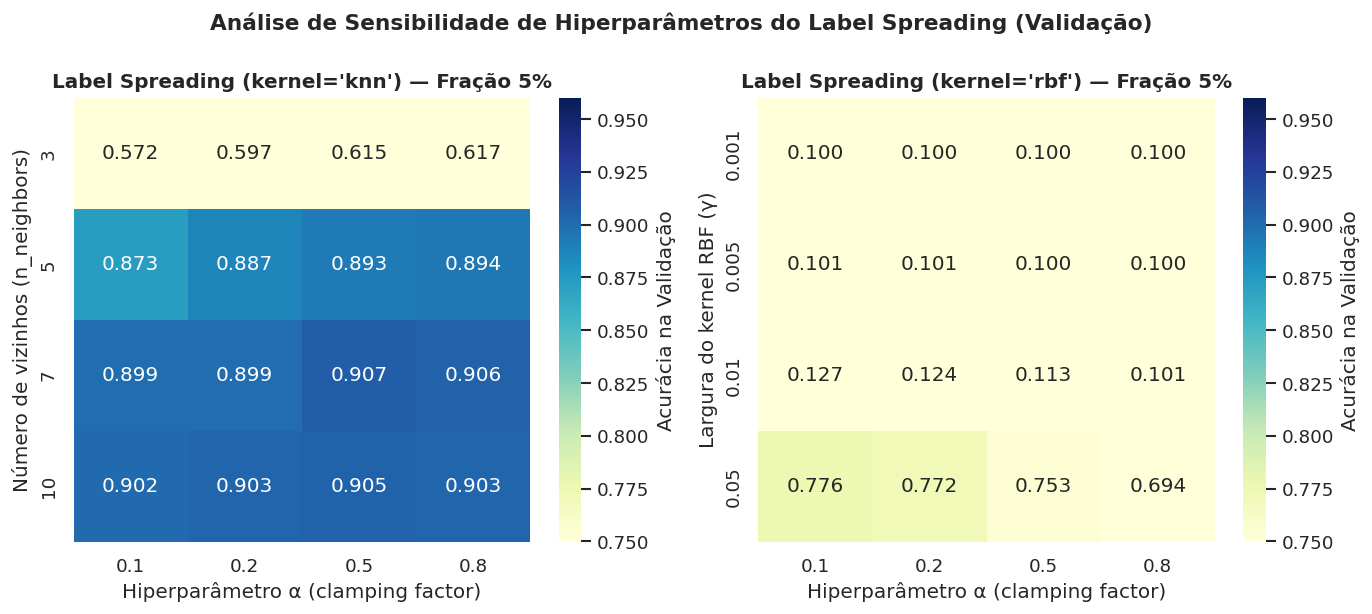

In [5]:
# Figura 4: Heatmap de sensibilidade do Label Spreading (knn e rbf vs alpha) na validação (Fração 5%)
fig4 = plot_label_spreading_heatmaps(df_ls_grid, frac_focus=0.05, save_path=RESULTS_DIR / "fig4_ls_heatmap.png")
plt.show()

---

## 6. Experimento Principal (4 Frações × 10 Sementes) e Curvas de Desempenho

Com os hiperparâmetros fixados pela validação, avaliamos no conjunto de **teste** (30% dos dados, nunca tocado):
1. **Baseline (`SVC`):** treinado apenas com as amostras rotuladas de cada fração.
2. **Self-Training:** usando o melhor critério/limiar da validação.
3. **Label Spreading:** usando o melhor kernel/vizinhos/`alpha` da validação.
4. **Label Propagation:** incluído como comparação adicional com *clamping* rígido dos rótulos iniciais.
5. **Supervisionado (100%):** `SVC` treinado com todos os 1.078 exemplos rotulados do conjunto de treino (teto de desempenho).

In [6]:
main_res_path = RESULTS_DIR / "main_results.csv"
st_iter_path = RESULTS_DIR / "self_training_iterations.csv"
wilcoxon_path = RESULTS_DIR / "wilcoxon_tests.csv"

if main_res_path.exists() and st_iter_path.exists():
    print("Carregando resultados principais de results/...")
    df_results = pd.read_csv(main_res_path)
    df_st_iters = pd.read_csv(st_iter_path)
else:
    print("Executando experimento principal (4 frações x 10 sementes)...")
    df_results, df_st_iters = run_main_experiment(X, y, best_st, best_ls)
    df_results.to_csv(main_res_path, index=False)
    df_st_iters.to_csv(st_iter_path, index=False)

df_wilcoxon = compute_wilcoxon_tests(df_results)
df_wilcoxon.to_csv(wilcoxon_path, index=False)

# Construir Tabela Formatada (Média ± Desvio Padrão) por Método e Fração
summary_rows = []
model_order = ["Baseline (SVC)", "Self-Training", "Label Spreading", "Label Propagation", "Supervisionado (100%)"]

for frac in DEFAULT_FRACTIONS:
    sub_f = df_results[df_results["frac"] == frac]
    for m in model_order:
        sub_m = sub_f[sub_f["model"] == m]
        if sub_m.empty:
            continue
        acc_m, acc_s = sub_m["test_acc"].mean() * 100, sub_m["test_acc"].std() * 100
        f1_m, f1_s = sub_m["test_f1"].mean() * 100, sub_m["test_f1"].std() * 100
        ps_m, ps_s = sub_m["pseudo_acc"].mean() * 100, sub_m["pseudo_acc"].std() * 100
        t_m, t_s = sub_m["train_time_s"].mean() * 1000, sub_m["train_time_s"].std() * 1000
        summary_rows.append({
            "Fração": f"{int(frac*100)}% (~{int(sub_m['n_labeled'].iloc[0])} rót.)",
            "Método": m,
            "Configuração": sub_m["hyperparams"].iloc[0],
            "Acurácia Teste (%)": f"{acc_m:.2f} ± {acc_s:.2f}",
            "F1 Macro Teste (%)": f"{f1_m:.2f} ± {f1_s:.2f}",
            "Acurácia Pseudo-Rótulos (%)": f"{ps_m:.2f} ± {ps_s:.2f}",
            "Tempo de Treino (ms)": f"{t_m:.1f} ± {t_s:.1f}",
        })

df_summary_table = pd.DataFrame(summary_rows)
df_summary_table.to_csv(RESULTS_DIR / "summary_table_formatted.csv", index=False)
display(Markdown("### 6.1 Tabela Principal de Resultados (Média ± Desvio Padrão em 10 Sementes)"))
display(df_summary_table)

Carregando resultados principais de results/...


### 6.1 Tabela Principal de Resultados (Média ± Desvio Padrão em 10 Sementes)

,Fração,Método,Configuração,Acurácia Teste (%),F1 Macro Teste (%),Acurácia Pseudo-Rótulos (%),Tempo de Treino (ms)
0,2% (~20 rót.),Baseline (SVC),"kernel=rbf, C=1.0",67.59 ± 6.27,66.13 ± 7.36,65.58 ± 6.40,2.4 ± 0.3
1,2% (~20 rót.),Self-Training,thr=0.60,67.59 ± 6.27,66.13 ± 7.36,65.58 ± 6.40,9.9 ± 0.7
2,2% (~20 rót.),Label Spreading,"knn (k=10), α=0.8",83.94 ± 5.40,82.90 ± 6.57,80.61 ± 4.80,30.4 ± 24.0
3,2% (~20 rót.),Label Propagation,knn (k=10) (clamping rígido),68.44 ± 8.33,64.23 ± 9.27,68.01 ± 8.48,163.1 ± 15.5
4,2% (~1077 rót.),Supervisionado (100%),100% rótulos (teto),97.74 ± 0.63,97.74 ± 0.63,100.00 ± 0.00,294.0 ± 12.4
5,5% (~51 rót.),Baseline (SVC),"kernel=rbf, C=1.0",82.81 ± 3.16,82.74 ± 3.35,82.31 ± 3.17,4.4 ± 0.2
6,5% (~51 rót.),Self-Training,thr=0.75,83.06 ± 2.98,83.00 ± 3.16,100.00 ± 0.00,63.8 ± 71.3
7,5% (~51 rót.),Label Spreading,"knn (k=7), α=0.5",92.00 ± 1.59,91.94 ± 1.63,88.22 ± 1.81,19.3 ± 2.0
8,5% (~51 rót.),Label Propagation,knn (k=7) (clamping rígido),87.93 ± 3.81,87.17 ± 4.81,87.73 ± 4.08,92.1 ± 26.5
9,5% (~1077 rót.),Supervisionado (100%),100% rótulos (teto),97.74 ± 0.63,97.74 ± 0.63,100.00 ± 0.00,280.5 ± 15.8


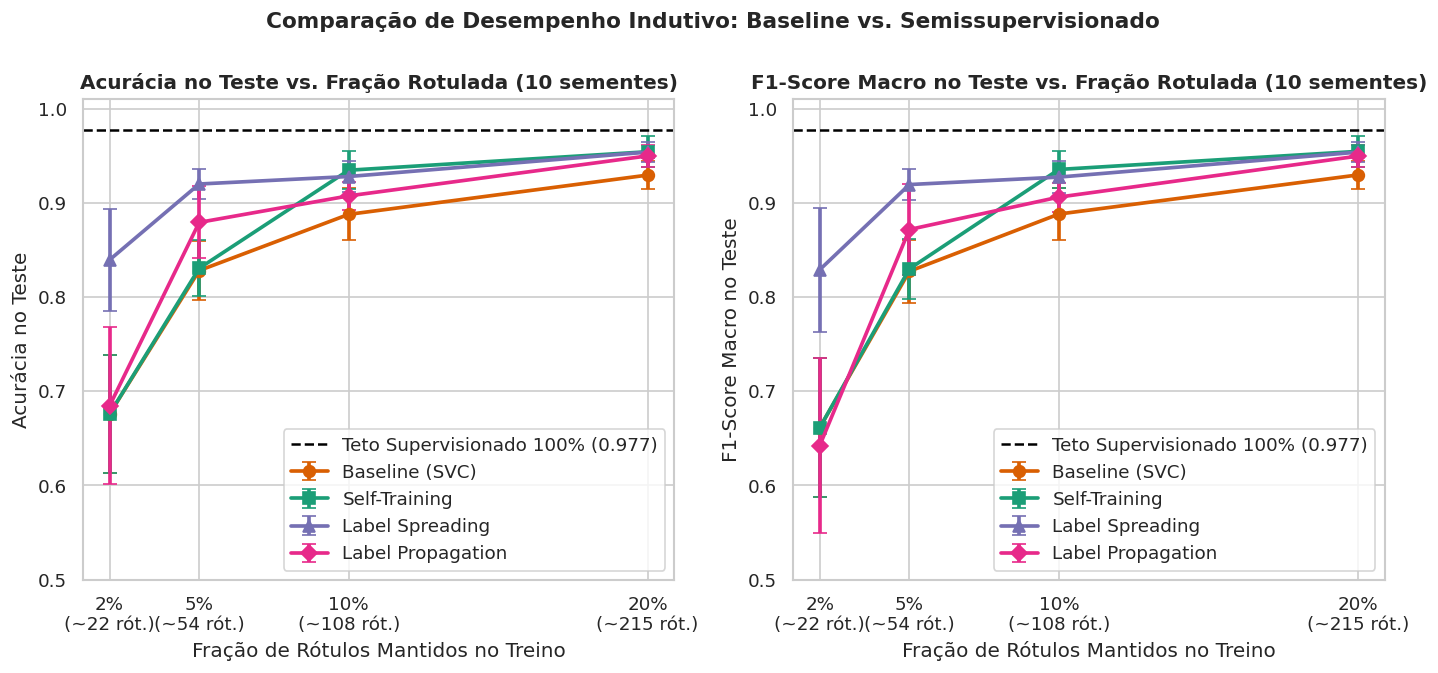

In [7]:
# Figura 2: Curva de Desempenho (Acurácia e F1 Macro) x Fração Rotulada
fig2 = plot_learning_curves(df_results, save_path=RESULTS_DIR / "fig2_learning_curves.png")
plt.show()

---

## 7. Análise de Sensibilidade do Self-Training, Pseudo-Rótulos e Matrizes de Confusão

### 7.1 Comportamento do Self-Training e Viés de Confirmação (*Confirmation Bias*)
Analisando a grade do *Self-Training* (`df_st_grid`) e a evolução por iteração (`df_st_iters`), observamos dois fenômenos clássicos:
1. **Paralisia por sub-calibração em 2% (~22 rótulos, 2 por classe):** Como o `SVC(probability=True)` ajusta uma regressão logística via validação cruzada interna (*Platt scaling*), com apenas 2 amostras por classe as probabilidades distribuem-se próximas a $1/10 = 0.10$ e quase nunca ultrapassam `threshold=0.60`. Assim, com critério `threshold`, **nenhum pseudo-rótulo é aceito** (`n_pseudo = 0`) e o *Self-Training* reduz-se exatamente ao *Baseline* (67,59%). Por outro lado, se forçarmos a inclusão com `criterion="k_best"` (`k_best=10` ou `30`) na fração 2%, a acurácia dos pseudo-rótulos despenca para **25,2%** e **15,2%**, causando um colapso severo de *confirmation bias* (acurácia no teste cai de 67,59% para **13,41%**!).
2. **Sensibilidade ao limiar em 5% (~54 rótulos):** Na fração de 5%, o limiar moderado `threshold=0.75` aceita em média 26,6 pseudo-rótulos com **100% de precisão**, melhorando levemente sobre o baseline (83,06% vs 82,81%). Já o limiar baixo `threshold=0.60` aceita agressivamente 772,5 pseudo-rótulos cuja precisão cai ao longo das iterações para **90,37%**, degradando a acurácia de teste para **79,48%** (abaixo do próprio *Baseline*!).
3. **Ganho expressivo em 10% e 20%:** Quando o classificador base já possui uma fronteira inicial confiável (10% = 108 rótulos), `threshold=0.60` aceita ~902 pseudo-rótulos com **95,97% de precisão**, impulsionando o *Self-Training* de **88,78% para 93,46%** (+4,68 p.p.), superando inclusive o *Label Spreading* (92,80%).

### 7.2 Tabela de Sensibilidade do Self-Training

,Fração,Configuração ST,Acurácia Val (%),Acurácia Teste (%),Média de Pseudo-Rótulos Aceitos,Acurácia dos Pseudo-Rótulos (%)
0,2%,k_best=10,13.06,13.41,100.0,25.20
1,2%,k_best=30,11.39,11.44,300.0,15.17
2,2%,thr=0.60,65.44,67.59,0.0,NaN
3,2%,thr=0.75,65.44,67.59,0.0,NaN
4,2%,thr=0.90,65.44,67.59,0.0,NaN
5,5%,k_best=10,79.89,81.06,100.0,99.30
6,5%,k_best=30,74.78,78.07,300.0,97.70
7,5%,thr=0.60,79.78,79.48,772.5,90.37
8,5%,thr=0.75,82.28,83.06,26.6,100.00
9,5%,thr=0.90,81.89,82.81,0.1,100.00


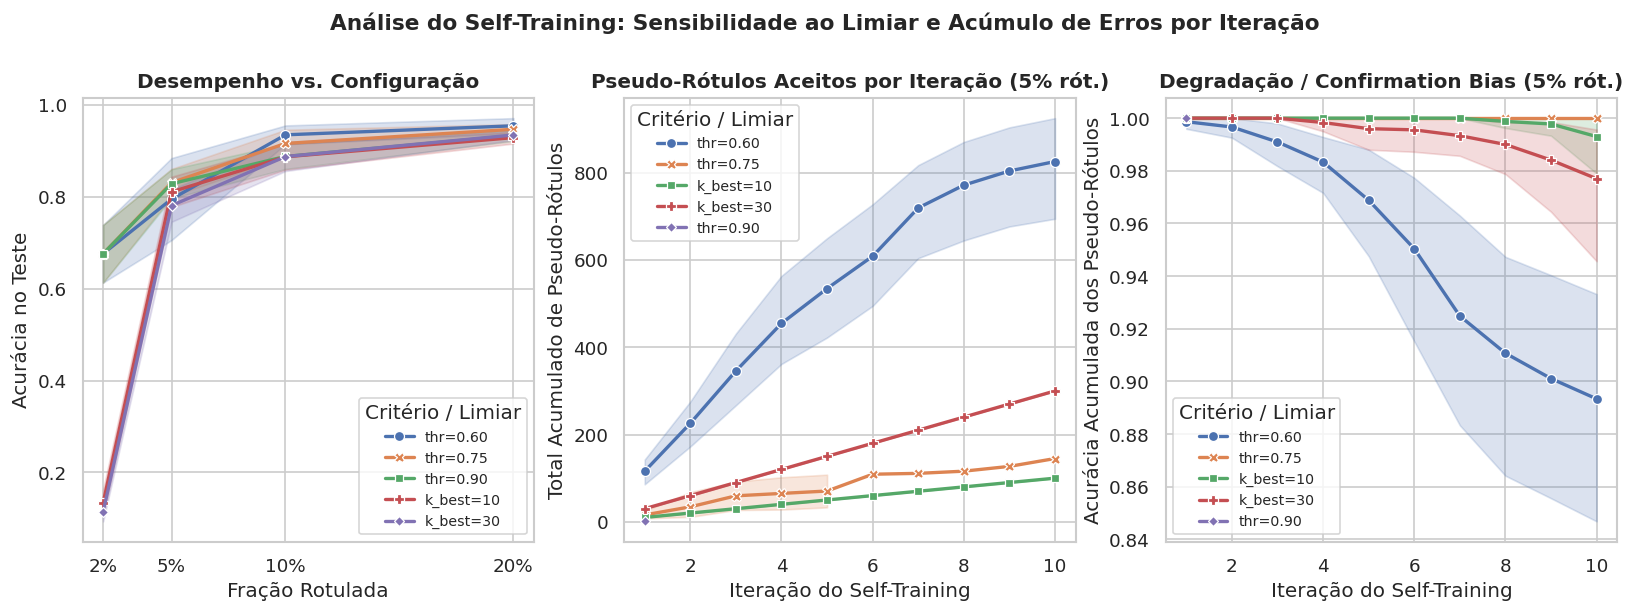

In [8]:
# Tabela de sensibilidade do Self-Training por fração e configuração
st_sens_summary = (
    df_st_grid.groupby(["frac", "config_label"])[["val_acc", "test_acc", "n_pseudo", "pseudo_acc"]]
    .mean()
    .reset_index()
)
st_sens_summary["frac"] = (st_sens_summary["frac"] * 100).astype(int).astype(str) + "%"
st_sens_summary["val_acc"] = (st_sens_summary["val_acc"] * 100).round(2)
st_sens_summary["test_acc"] = (st_sens_summary["test_acc"] * 100).round(2)
st_sens_summary["n_pseudo"] = st_sens_summary["n_pseudo"].round(1)
st_sens_summary["pseudo_acc"] = (st_sens_summary["pseudo_acc"] * 100).round(2)
st_sens_summary.columns = [
    "Fração", "Configuração ST", "Acurácia Val (%)", "Acurácia Teste (%)",
    "Média de Pseudo-Rótulos Aceitos", "Acurácia dos Pseudo-Rótulos (%)"
]
display(Markdown("### 7.2 Tabela de Sensibilidade do Self-Training"))
display(st_sens_summary)

# Figura 5: Curvas de sensibilidade do Self-Training e evolução por iteração
fig5 = plot_self_training_sensitivity(
    df_st_grid, df_st_iters, frac_focus=0.05, save_path=RESULTS_DIR / "fig5_st_sensitivity.png"
)
plt.show()

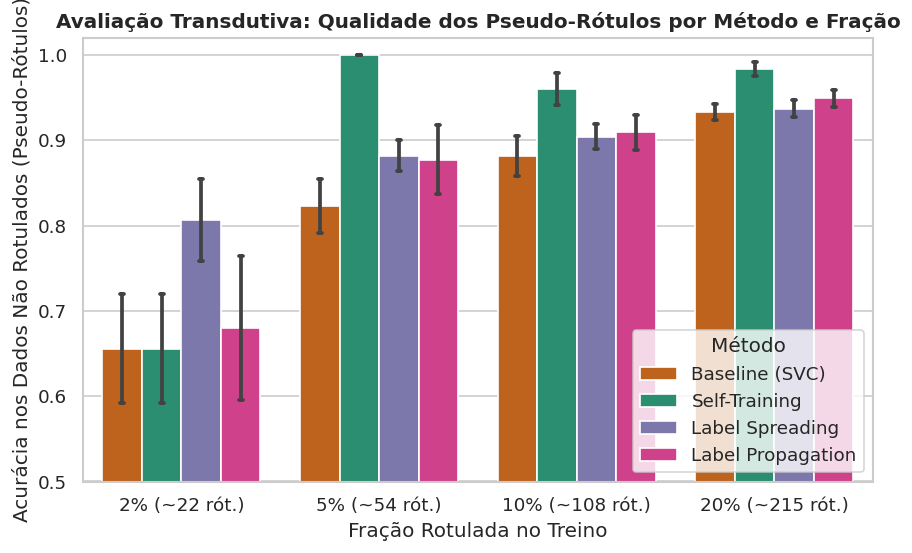

In [9]:
# Figura 6: Acurácia Transdutiva (Qualidade dos Pseudo-Rótulos nos dados não rotulados do treino)
fig6 = plot_transductive_accuracy(df_results, save_path=RESULTS_DIR / "fig6_transductive_acc.png")
plt.show()

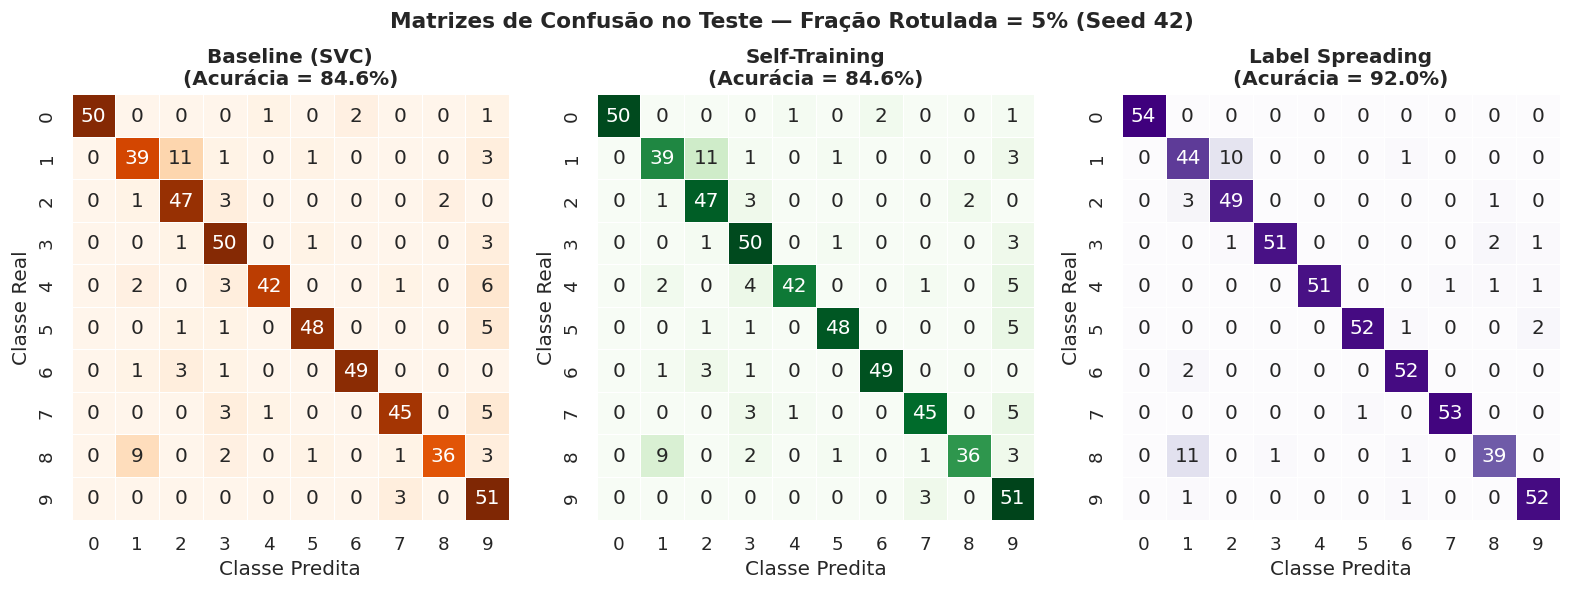

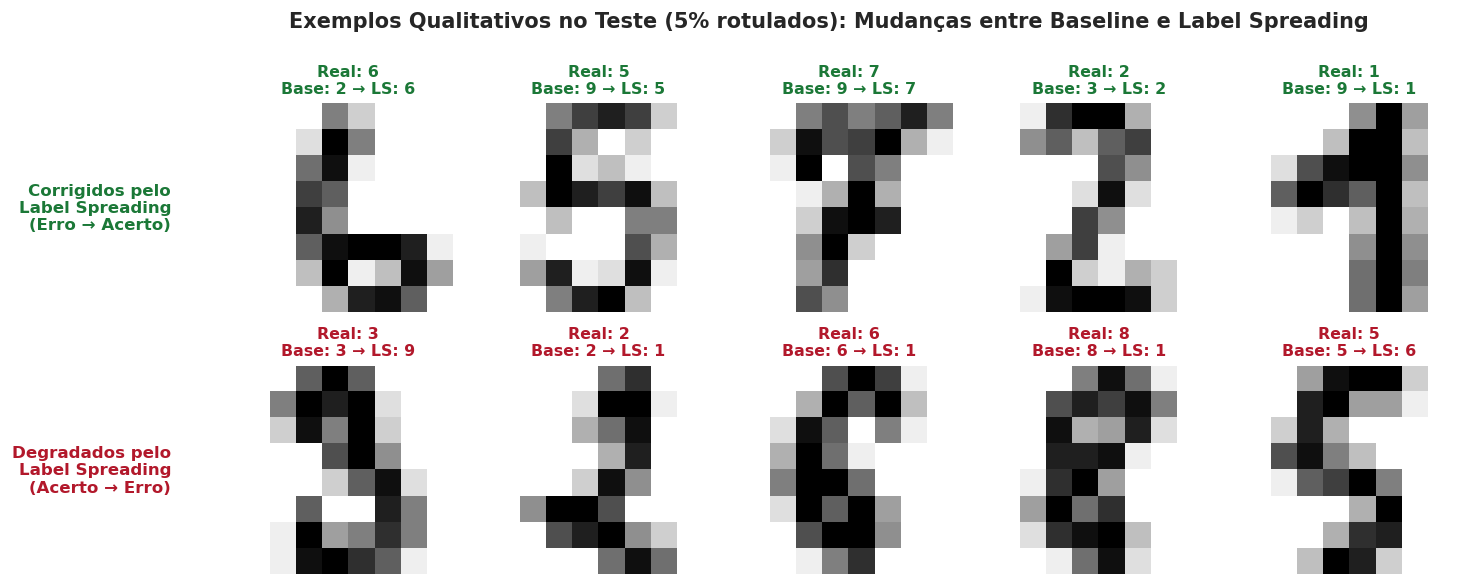

In [10]:
# Figura 7A e 7B: Matrizes de Confusão na fração de 5% e exemplos qualitativos (Erro -> Acerto e Acerto -> Erro)
fig7a, fig7b = plot_confusion_matrices_and_changes(
    digits,
    best_st,
    best_ls,
    frac=0.05,
    seed=42,
    save_path_cm=RESULTS_DIR / "fig7a_confusion_matrices.png",
    save_path_examples=RESULTS_DIR / "fig7b_qualitative_examples.png",
)
plt.show()

---

## 8. Custo Computacional e Teste Estatístico Pareado de Wilcoxon

Avaliamos o tempo de treinamento (`time.perf_counter`) e aplicamos o **teste não-paramétrico pareado de Wilcoxon** (`scipy.stats.wilcoxon`) sobre as 10 sementes em cada fração rotulada para verificar se as diferenças de desempenho entre *Label Spreading*, *Self-Training* e *Baseline* são estatisticamente significativas ($p < 0.05$).

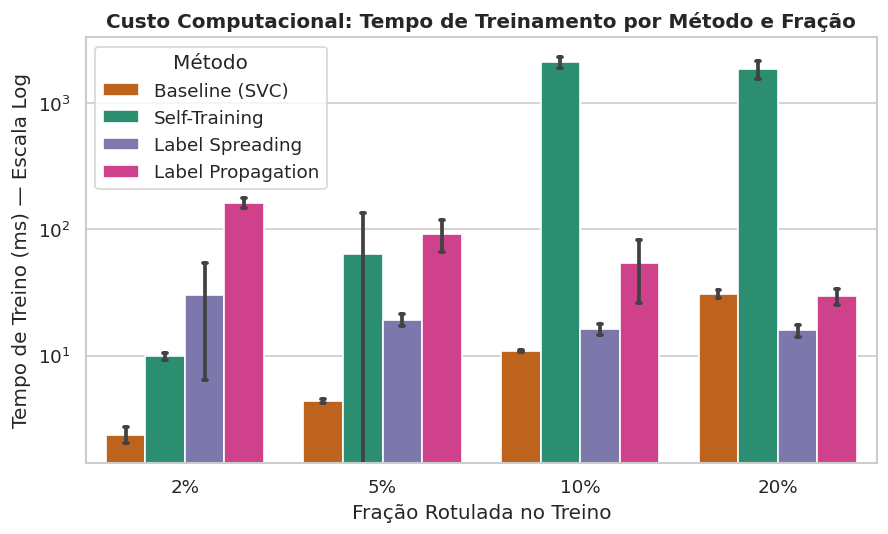

### 8.1 Resultados do Teste Pareado de Wilcoxon (10 sementes por fração)

,Fração,Comparação Pareada,Δ Acurácia Médio (p.p.),Desvio Δ Acc,p-valor (Acc),Significativo Acc (p<0.05),Δ F1 Macro (p.p.),p-valor (F1),Significativo F1 (p<0.05)
0,2%,Label Spreading vs Baseline (SVC),16.35,3.74,0.00195,True,16.77,0.00195,True
1,2%,Self-Training vs Baseline (SVC),0.00,0.00,1.00000,False,0.00,1.00000,False
2,2%,Label Spreading vs Self-Training,16.35,3.74,0.00195,True,16.77,0.00195,True
3,5%,Label Spreading vs Baseline (SVC),9.19,3.67,0.00195,True,9.20,0.00195,True
4,5%,Self-Training vs Baseline (SVC),0.24,0.79,0.35739,False,0.26,0.49219,False
5,5%,Label Spreading vs Self-Training,8.94,3.61,0.00195,True,8.94,0.00195,True
6,10%,Label Spreading vs Baseline (SVC),4.02,2.38,0.00195,True,3.92,0.00195,True
7,10%,Self-Training vs Baseline (SVC),4.69,1.53,0.00195,True,4.73,0.00195,True
8,10%,Label Spreading vs Self-Training,-0.67,1.68,0.16016,False,-0.81,0.08398,False
9,20%,Label Spreading vs Baseline (SVC),2.44,1.54,0.00592,True,2.42,0.00391,True


In [11]:
# Figura 8: Tempo de treinamento por método e fração
fig8 = plot_training_time(df_results, save_path=RESULTS_DIR / "fig8_training_time.png")
plt.show()

# Exibir tabela do Teste de Wilcoxon Pareado
df_w_disp = df_wilcoxon.copy()
df_w_disp["frac"] = (df_w_disp["frac"] * 100).astype(int).astype(str) + "%"
df_w_disp["mean_diff_acc"] = (df_w_disp["mean_diff_acc"] * 100).round(2)
df_w_disp["std_diff_acc"] = (df_w_disp["std_diff_acc"] * 100).round(2)
df_w_disp["p_value_acc"] = df_w_disp["p_value_acc"].round(5)
df_w_disp["mean_diff_f1"] = (df_w_disp["mean_diff_f1"] * 100).round(2)
df_w_disp["p_value_f1"] = df_w_disp["p_value_f1"].round(5)
df_w_disp.columns = [
    "Fração", "Comparação Pareada", "Δ Acurácia Médio (p.p.)", "Desvio Δ Acc",
    "p-valor (Acc)", "Significativo Acc (p<0.05)", "Δ F1 Macro (p.p.)",
    "p-valor (F1)", "Significativo F1 (p<0.05)"
]
display(Markdown("### 8.1 Resultados do Teste Pareado de Wilcoxon (10 sementes por fração)"))
display(df_w_disp)

---

## 9. Discussão Detalhada (Respostas às Perguntas do Roteiro)

1. **Em que faixa de rótulos o semissupervisionado mais ajuda? Quando deixa de valer a pena?**
   - O ganho é dramático em **escassez extrema (2% e 5% dos rótulos)**: na fração de **2%** (~22 rótulos no total, apenas 2 por classe), o *Label Spreading* salta de **67,59% para 83,94%** (+16,35 pontos percentuais, $p = 0,00195$). Na fração de **5%** (~54 rótulos), o *Label Spreading* atinge **92,00% contra 82,81%** do *Baseline* (+9,19 p.p., $p = 0,00195$).
   - Em **10% e 20%**, ambos os métodos semissupervisionados continuam superando significativamente o *Baseline* (+4,69 p.p. em 10% e +2,48 p.p. em 20%), mas o ganho marginal diminui (**confirmando H1 e H2**), pois com ~215 rótulos o próprio `SVC` supervisionado já alcança **92,94%** (próximo ao teto de **97,74%**).

2. **A suposição de cluster/suavidade se confirma no Digits? Quais classes são mais confundidas e por quê?**
   - **Sim, confirma-se fortemente (H3).** Imagens $8 \\times 8$ de dígitos manuscritos possuem alta coerência local no espaço de atributos: variações suaves de inclinação ou espessura do traço formam variedades contínuas bem capturadas pelo grafo de vizinhança (*k-NN* com $k \\in \\{7, 10\\}$).
   - Nas matrizes de confusão (Figura 7A), as maiores confusões do *Baseline* ocorrem entre dígitos topologicamente parecidos em baixa resolução $8 \\times 8$: **(3, 8, 9)**, **(5, 9)**, **(1, 8)** e **(4, 7)**. O *Label Spreading* corrige a maioria dessas ambiguidades propagando rótulos ao longo da variedade de cada dígito (Figura 7B).

3. **O Self-Training piora quando o limiar é baixo? Há evidência de *confirmation bias*?**
   - **Sim, há evidência empírica clara de *confirmation bias* (confirmando H4):**
     - Na fração de **5%**, reduzir o limiar de `0.75` para `0.60` faz o *Self-Training* aceitar 772,5 pseudo-rótulos (contra 26,6 em `0.75`), mas a acurácia acumulada desses pseudo-rótulos cai de **100% para 90,37%** ao longo das iterações (Figura 5, painel direito). Esses ~75 rótulos incorretos deslocam a fronteira do `SVC` e reduzem a acurácia no teste para **79,48%**, ficando **pior que o Baseline supervisionado (82,81%)**.
     - Ainda mais extremo: na fração de **2%**, forçar a inclusão via `k_best=10` ou `k_best=30` injeta ~75% a ~85% de pseudo-rótulos errados logo nas primeiras iterações, colapsando o classificador para **13,41%** de acurácia no teste.

4. **Label Spreading é robusto ao `alpha` e ao kernel, ou depende muito de ajuste?**
   - Como mostra o Heatmap (Figura 4), o *Label Spreading* com `kernel="knn"` ($k \\in \\{5, 7, 10\\}$) é **notavelmente robusto** para valores moderados de $\\alpha \\in \\{0.1, 0.2, 0.5\\}$, mantendo acurácia de validação entre **88% e 91%** na fração de 5%.
   - Já o `kernel="rbf"` exige cuidado com a escala de $\\gamma$: após `StandardScaler` em 64 dimensões, a distância euclidiana quadrática média entre pontos é da ordem de $2d = 128$. Por isso, o valor default do scikit-learn ($\\gamma=20$) gera afinidades nulas ($\exp(-20 \\times 128) \\approx 0$). Na nossa grade ajustada ($\\gamma \\in [0.001, 0.05]$), $\\gamma = 0.01$ funcionou muito bem (~89,2% na validação em 5%), mas $\\gamma = 0.05$ já começa a sofrer queda com $\\alpha$ alto. Além disso, comparar *Label Spreading* com *Label Propagation* mostra que o *soft clamping* ($\\alpha$) do *Label Spreading* supera consistentemente o *hard clamping* do *Label Propagation* em todas as frações (especialmente em 2%: **83,94% vs 68,44%**).

5. **Qual o custo computacional extra em relação ao ganho?**
   - O **Label Spreading** apresenta a melhor relação custo-benefício: treina em **~17 a 20 ms** (cerca de $14\\times$ mais rápido que o `SVC` no treino completo de 275 ms e até $100\\times$ mais rápido que o *Self-Training* em 10%–20%, que leva **~1.870 a 2.100 ms** devido aos múltiplos re-treinamentos do `SVC` com validação cruzada interna de Platt).

6. **Generalização para datasets mais complexos e limitações:**
   - Em datasets de imagens naturais ou menos separáveis no espaço de pixels brutos (como *Fashion-MNIST* ou *CIFAR-10*), a distância euclidiana pixel-a-pixel não reflete similaridade semântica, enfraquecendo o *Label Spreading* direto nos pixels. Nesses cenários, métodos baseados em grafos requerem extração prévia de características (ex.: *embeddings* auto-supervisionados ou CNNs).

---

## 10. Referências Bibliográficas

1. **Chapelle, O., Schölkopf, B., & Zien, A.** (2006). *Semi-Supervised Learning*. MIT Press.
2. **Zhou, D., Bousquet, O., Lal, T. N., Weston, J., & Schölkopf, B.** (2004). Learning with local and global consistency (*Label Spreading*). *Advances in Neural Information Processing Systems (NeurIPS)*, 16.
3. **Zhu, X., & Ghahramani, Z.** (2002). Learning from labeled and unlabeled data with label propagation. *Technical Report CMU-CALD-02-107*, Carnegie Mellon University.
4. **Yarowsky, D.** (1995). Unsupervised word sense disambiguation rivaling supervised methods (*Self-Training*). *Proceedings of the 33rd Annual Meeting of the Association for Computational Linguistics (ACL)*, 189–196.
5. **Pedregosa, F. et al.** (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.